# Laboratory Exercise 2: Mobile Plans

Telekomuna is a mobile operator in Macedonia. Its export in `data/customers.csv` holds one row per customer who signed a postpaid contract, and `data/daily-activations.csv` counts the contracts activated on each day. The customers are synthetic and describe no real person or operator, and the device models are invented.

The columns of `customers.csv` are these:

- `customer_id`, the identifier of the customer, and `signed_on`, the day the contract was signed,
- `device_model`, the model of the customer's phone, and `origin`, which is a new number, a number ported from another operator, or an upgrade,
- `contract`, a personal or a business contract, and `lines`, the number of SIM cards on the contract, as the system recorded it,
- `package`, one of small, medium, large, extra large, and unlimited,
- `payment`, the way the customer pays, and `handset`, a phone financed by the operator or the customer's own device, with `instalment`, the monthly instalment for the phone in denars,
- `calls`, the calls in the first month, and `call_minutes`, the minutes of those calls,
- `data_gb`, the mobile data used in the first month in gigabytes, `deposit`, the deposit in denars that a credit check set at signing, and `sms`, the text messages sent in the first month, and
- `monthly_bill`, the bill of the first month in denars, which a later model will predict.

The customers are to be prepared for that model: every gap filled for a reason, every unusual value understood, every label turned into numbers, and every column brought to a comparable scale, with every step learned from the training customers alone. No request asks for a model.

Answer each request in the cells below it, and add as many cells as you need. The laboratory test asks for values and decisions that your notebook computes, so keep every result visible, run the notebook from top to bottom before you submit it, and make sure it runs on a machine without internet access.

## Setup

The cells in this section are written already. Run them before the tasks.

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import IsolationForest
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, KNNImputer, MissingIndicator, SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import LocalOutlierFactor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import (MinMaxScaler, OneHotEncoder, OrdinalEncoder, PowerTransformer, RobustScaler,
                                   StandardScaler)

DATA = Path("data")
# Every random step uses this seed, so a rerun gives the same result.
SEED = 2026

In [6]:
# The course style.
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#1e2a24"]
GROUND, INK, GRID = "#ffffff", "#1e2a24", "#e2e6e4"
plt.rcParams.update(
    {
        "figure.figsize": (8, 4.5),
        "figure.facecolor": GROUND,
        "figure.constrained_layout.use": True,
        "savefig.facecolor": GROUND,
        "savefig.transparent": False,
        "font.family": "sans-serif",
        "font.sans-serif": ["Archivo", "DejaVu Sans"],
        "font.size": 12,
        "text.color": INK,
        "axes.facecolor": GROUND,
        "axes.edgecolor": INK,
        "axes.labelcolor": INK,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.prop_cycle": plt.cycler(color=PALETTE),
        "grid.color": GRID,
        "xtick.color": INK,
        "ytick.color": INK,
        "legend.frameon": False,
        "image.cmap": "cividis",
    }
)
sns.set_palette(PALETTE)

In [7]:
class FrequencyEncoder(TransformerMixin, BaseEstimator):
    """Replaces each category with its share of the rows passed to fit, and an unseen category with 0."""

    def fit(self, X: pd.DataFrame, y: object = None) -> "FrequencyEncoder":
        self.shares_ = {column: X[column].value_counts(normalize=True) for column in X.columns}
        return self

    def transform(self, X: pd.DataFrame) -> np.ndarray:
        return np.column_stack([X[column].map(share).fillna(0).to_numpy(dtype=float)
                                for column, share in self.shares_.items()])

    def get_feature_names_out(self, input_features: object = None) -> np.ndarray:
        return np.array([f"{column}_frequency" for column in self.shares_])

In [8]:
customers = pd.read_csv(DATA / "customers.csv")
daily_activations = pd.read_csv(DATA / "daily-activations.csv")
customers.head()

,customer_id,signed_on,device_model,contract,origin,package,payment,handset,calls,call_minutes,data_gb,lines,instalment,deposit,sms,monthly_bill
0,91001,2024-12-03,Kestrel A3,personal,new number,small,direct debit,financed,28,93,18.5,2,450,7850,8,1000
1,91002,2024-12-03,Aster 12,personal,new number,medium,card,financed,24,76,11.5,2,450,860,10,1174
2,91003,2024-12-05,Terra 6,personal,new number,extra large,direct debit,financed,148,449,9.7,1,450,2330,28,1627
3,91004,2024-12-06,Lumo 4,personal,upgrade,small,bank transfer,financed,100,294,4.3,1,450,1850,30,x
4,91005,2024-12-06,Lark 21,personal,new number,extra large,cash,financed,59,165,9.7,1,900,1450,7,2019


## Task 1: The Gaps

### 1.1 Reading the Gaps

The file writes a value it does not have with a marker of its own. Read the customers into a table named `df` in which every such value is missing. Count the missing values in each column, and show where they fall.

Missing values per column:
call_minutes    77
instalment      41
payment         22
data_gb         19
monthly_bill     8
dtype: int64


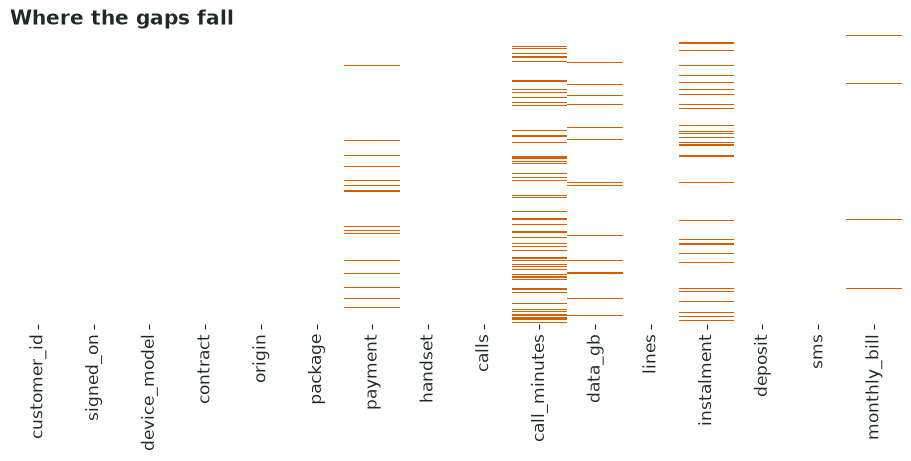

In [9]:
# Write your solution here.
df = pd.read_csv(DATA / "customers.csv", na_values="x")

missing_counts = df.isna().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)
print("Missing values per column:")
print(missing_counts)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap=[GROUND, PALETTE[1]], ax=ax)
ax.set_title("Where the gaps fall")
ax.set_xlabel("")
plt.show()

### 1.2 Why Values Are Missing

For each column with missing values, find out whether its gaps depend on another column, whether a gap means that the value does not exist, or whether the gaps follow no pattern. Show the comparison that decides each case.

In [10]:
# Write your solution here.
missing_cols = missing_counts.index.tolist()
cat_cols = ["contract", "origin", "package", "handset"]
num_cols = ["calls", "deposit", "sms", "lines"]

rows = []
for col in missing_cols:
    flag = df[col].isna()
    for c in cat_cols:
        chi2, p, dof, exp = stats.chi2_contingency(pd.crosstab(flag, df[c]))
        rows.append({"column": col, "compared_to": c, "test": "chi-square", "p_value": p})
    for c in num_cols:
        a, b = df.loc[flag, c].dropna(), df.loc[~flag, c].dropna()
        t, p = stats.ttest_ind(a, b, equal_var=False)
        rows.append({"column": col, "compared_to": c, "test": "t-test", "p_value": p})

pattern_tests = pd.DataFrame(rows).sort_values(["column", "p_value"]).reset_index(drop=True)
print("Comparisons with p < 0.05 (missing vs. not-missing rows):")
print(pattern_tests[pattern_tests["p_value"] < 0.05].to_string(index=False))

print("\ninstalment vs. handset -- a perfect split, so the value does not exist rather than being unknown:")
print(pd.crosstab(df["instalment"].isna(), df["handset"]))

print("\ncall_minutes vs. origin -- missing far more often for ported numbers (depends on another column):")
print(pd.crosstab(df["call_minutes"].isna(), df["origin"], normalize="columns").round(3))

print("\npayment and data_gb show no significant, outlier-free relationship to any other column: no pattern.")
print("The 'lines' associations above are driven by just a couple of extreme lines values landing by")
print("chance in the small missing groups (see Task 3.1), not a genuine dependency.")

Comparisons with p < 0.05 (missing vs. not-missing rows):
      column compared_to       test      p_value
call_minutes      origin chi-square 6.357504e-18
call_minutes         sms     t-test 7.879918e-03
call_minutes       lines     t-test 4.458942e-02
     data_gb       lines     t-test 2.397635e-03
  instalment     handset chi-square 1.233861e-86
monthly_bill       lines     t-test 4.077159e-02

instalment vs. handset -- a perfect split, so the value does not exist rather than being unknown:
handset     financed  own device
instalment                      
False            359           0
True               0          41

call_minutes vs. origin -- missing far more often for ported numbers (depends on another column):
origin        new number  ported  upgrade
call_minutes                             
False              0.957   0.583    0.926
True               0.043   0.417    0.074

payment and data_gb show no significant, outlier-free relationship to any other column: no pattern.


### 1.3 What Deleting Would Cost

Find out how many customers would remain if every customer with a missing value were dropped, and how the mix of origins would change. Then decide what to do with the customers that state no monthly bill, and apply the decision to `df`.

In [11]:
# Write your solution here.
complete_rows = df.dropna()
print(f"Complete-case customers: {len(complete_rows)} of {len(df)} ({len(complete_rows) / len(df):.1%})")

print("\nOrigin mix, all customers:")
print(df["origin"].value_counts(normalize=True).round(3))
print("\nOrigin mix, complete-case customers:")
print(complete_rows["origin"].value_counts(normalize=True).round(3))
print("\nDropping every row with any gap would disproportionately remove 'ported' customers (their share")
print("falls from 37.8% to 27.9%), because they drive most of the call_minutes gaps -- a biased subset,")
print("not a reason to drop wholesale.")

n_before = len(df)
df = df.dropna(subset=["monthly_bill"]).reset_index(drop=True)
print(f"\nmonthly_bill is the prediction target: a row with no label can't be trained on or checked against,")
print(f"so (unlike the other gaps) these rows are dropped outright.")
print(f"Dropped {n_before - len(df)} customers with no stated monthly bill; {len(df)} remain.")

Complete-case customers: 258 of 400 (64.5%)

Origin mix, all customers:
origin
ported        0.378
new number    0.352
upgrade       0.270
Name: proportion, dtype: float64

Origin mix, complete-case customers:
origin
new number    0.415
upgrade       0.306
ported        0.279
Name: proportion, dtype: float64

Dropping every row with any gap would disproportionately remove 'ported' customers (their share
falls from 37.8% to 27.9%), because they drive most of the call_minutes gaps -- a biased subset,
not a reason to drop wholesale.

monthly_bill is the prediction target: a row with no label can't be trained on or checked against,
so (unlike the other gaps) these rows are dropped outright.
Dropped 8 customers with no stated monthly bill; 392 remain.


## Task 2: The Split and the Fills

### 2.1 The Test Customers

The customers who signed on 1 September 2025 or later stand in for customers that the preparation has never seen. Set them aside as the test customers, `X_test` and `y_test`, and keep the earlier customers as the training customers, `X_train` and `y_train`, where `X` holds every column except the monthly bill and `y` holds the monthly bill. Every later step learns only from the training customers. Report the number of each.

In [12]:
# Write your solution here.
df["signed_on"] = pd.to_datetime(df["signed_on"])
split_date = pd.Timestamp("2025-09-01")
train_mask = df["signed_on"] < split_date
test_mask = ~train_mask

X = df.drop(columns="monthly_bill")
y = df["monthly_bill"]

X_train = X.loc[train_mask].reset_index(drop=True)
y_train = y.loc[train_mask].reset_index(drop=True)
X_test = X.loc[test_mask].reset_index(drop=True)
y_test = y.loc[test_mask].reset_index(drop=True)

print(f"Training customers: {len(X_train)}")
print(f"Test customers: {len(X_test)}")

Training customers: 294
Test customers: 98


### 2.2 Filling the Gaps

Fill the gaps of each column in the way its pattern calls for, learning every fill from the training customers, and keep a record of the filled values wherever the absence itself carries information. Report the value that each fill by a single value uses.

In [14]:
# Write your solution here.
for frame in (X_train, X_test):
    frame["instalment"] = frame["instalment"].where(frame["handset"] != "own device", 0.0)
instalment_fill = X_train.loc[X_train["handset"] == "financed", "instalment"].median()
for frame in (X_train, X_test):
    frame["instalment"] = frame["instalment"].fillna(instalment_fill)

# payment: no pattern found (Task 1.2) -> training mode
payment_fill = X_train["payment"].mode().iat[0]
for frame in (X_train, X_test):
    frame["payment"] = frame["payment"].fillna(payment_fill)

# data_gb: no pattern found (Task 1.2) -> training median
data_gb_fill = X_train["data_gb"].median()
for frame in (X_train, X_test):
    frame["data_gb"] = frame["data_gb"].fillna(data_gb_fill)

# call_minutes: depends on origin (mostly "ported") -> per-origin training median, and a flag,
# since *being* missing is itself informative here.
call_minutes_fill = X_train.groupby("origin")["call_minutes"].median()
for frame in (X_train, X_test):
    frame["call_minutes_missing"] = frame["call_minutes"].isna().astype(int)
    frame["call_minutes"] = frame["call_minutes"].fillna(frame["origin"].map(call_minutes_fill))

print("instalment fill (financed customers, median):", instalment_fill)
print("payment fill (mode):", payment_fill)
print("data_gb fill (median):", data_gb_fill)
print("\ncall_minutes fill (per-origin median):")
print(call_minutes_fill)

print("\nRemaining missing values (training):")
print(X_train.isna().sum()[X_train.isna().sum() > 0])
print("Remaining missing values (test):")
print(X_test.isna().sum()[X_test.isna().sum() > 0])

instalment fill (financed customers, median): 900.0
payment fill (mode): direct debit
data_gb fill (median): 8.7

call_minutes fill (per-origin median):
origin
new number    182.0
ported        188.0
upgrade       177.5
Name: call_minutes, dtype: float64

Remaining missing values (training):
Series([], dtype: int64)
Remaining missing values (test):
Series([], dtype: int64)


### 2.3 How Well a Fill Recovers the Minutes

Hide the known call minutes of every training customer whose identifier is divisible by five. Fill these minutes back in three ways, all from the numeric columns: with the median minutes, from the five most similar customers judged on standardized columns, and by predicting each column from the others in rounds with the seed 2026. Measure how far each fill lies from the true minutes on average, and show the filled minutes against the true ones.

Hiding 46 known call-minute values.
      median: mean absolute error = 91.3 minutes
   KNN (k=5): mean absolute error = 51.4 minutes
   iterative: mean absolute error = 24.7 minutes


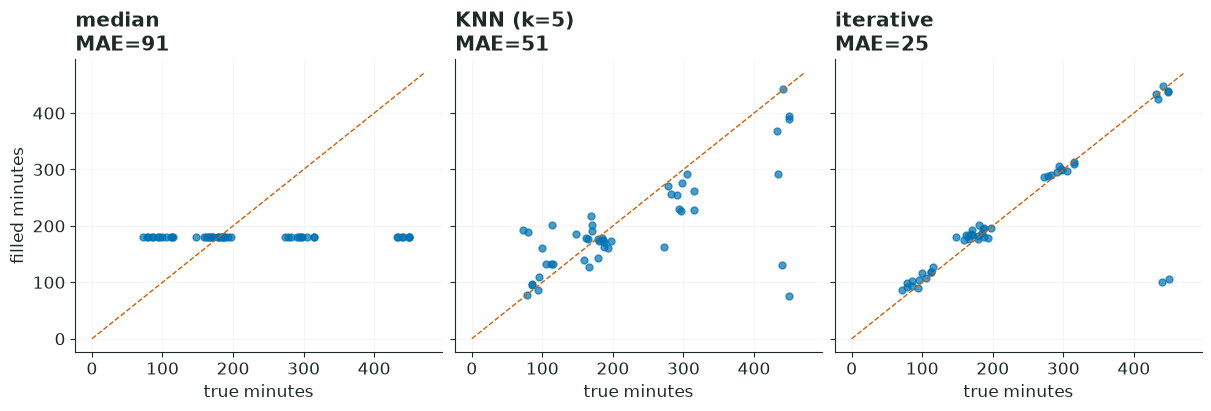

In [15]:
# Write your solution here.
numeric_candidates = ["calls", "call_minutes", "data_gb", "lines", "deposit", "sms", "instalment"]

# Rebuild the training customers *before* the 2.2 fill, so there are true values to hide and recover.
raw = pd.read_csv(DATA / "customers.csv", na_values="x").dropna(subset=["monthly_bill"]).reset_index(drop=True)
raw["signed_on"] = pd.to_datetime(raw["signed_on"])
raw_train = raw.loc[raw["signed_on"] < split_date].reset_index(drop=True)

hide_mask = (raw_train["customer_id"] % 5 == 0) & raw_train["call_minutes"].notna()
true_minutes = raw_train.loc[hide_mask, "call_minutes"]
print(f"Hiding {hide_mask.sum()} known call-minute values.")

eval_df = raw_train[numeric_candidates].copy()
eval_df.loc[hide_mask, "call_minutes"] = np.nan
known = eval_df.loc[~hide_mask]

# (a) median
pred_median = pd.Series(eval_df["call_minutes"].fillna(known["call_minutes"].median()), index=eval_df.index).loc[hide_mask]

# (b) 5-nearest-neighbours on standardized numeric columns
scaler = StandardScaler().set_output(transform="pandas").fit(known)
knn_imputer = KNNImputer(n_neighbors=5).set_output(transform="pandas").fit(scaler.transform(known))
knn_filled = scaler.inverse_transform(knn_imputer.transform(scaler.transform(eval_df)))
pred_knn = pd.DataFrame(knn_filled, columns=numeric_candidates, index=eval_df.index).loc[hide_mask, "call_minutes"]

# (c) round-robin model-based imputation
it_imputer = IterativeImputer(random_state=SEED).fit(known)
it_filled = pd.DataFrame(it_imputer.transform(eval_df), columns=numeric_candidates, index=eval_df.index)
pred_iter = it_filled.loc[hide_mask, "call_minutes"]

mae = {}
for name, pred in [("median", pred_median), ("KNN (k=5)", pred_knn), ("iterative", pred_iter)]:
    mae[name] = (pred - true_minutes).abs().mean()
    print(f"{name:>12}: mean absolute error = {mae[name]:.1f} minutes")

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
for ax, (name, pred) in zip(axes, [("median", pred_median), ("KNN (k=5)", pred_knn), ("iterative", pred_iter)]):
    ax.scatter(true_minutes, pred, color=PALETTE[0], alpha=0.7, s=25)
    lims = [0, max(true_minutes.max(), pred.max()) * 1.05]
    ax.plot(lims, lims, color=PALETTE[1], linewidth=1, linestyle="--")
    ax.set_title(f"{name}\nMAE={mae[name]:.0f}")
    ax.set_xlabel("true minutes")
axes[0].set_ylabel("filled minutes")
plt.show()

### 2.4 Gaps in Time

`daily_activations` counts the contracts activated on each day, and a day without a row was not recorded. Make every day of the period visible, then fill each gap from the neighbouring days, at most three days into a gap and only between recorded days. Report how many days are missing before the fill and how many stay missing after it, and show the series around its longest gap.

Missing days before the fill: 26
Missing days after the fill (gaps over 3 days stay open): 10
Longest gap: 13 days


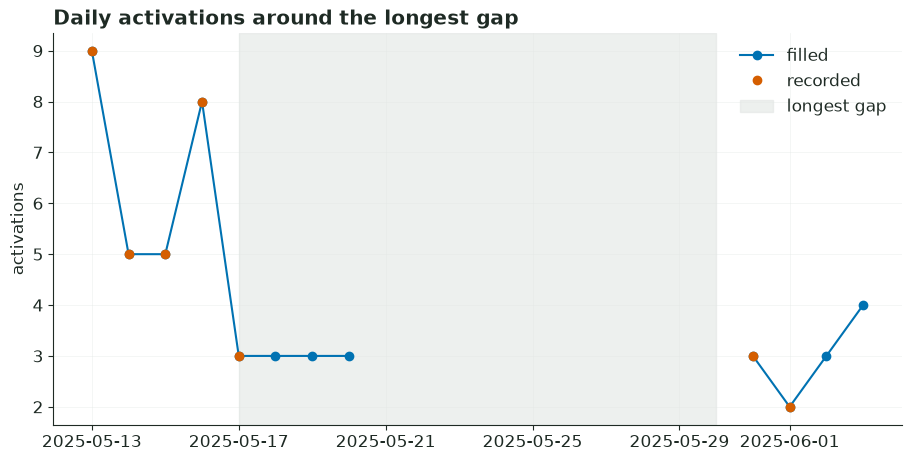

In [16]:
# Write your solution here.
daily_activations["date"] = pd.to_datetime(daily_activations["date"])
full_range = pd.date_range(daily_activations["date"].min(), daily_activations["date"].max(), freq="D")
activations_full = daily_activations.set_index("date").reindex(full_range)
activations_full.index.name = "date"

missing_before = activations_full["activations"].isna().sum()
activations_full["activations_filled"] = activations_full["activations"].interpolate(
    method="linear", limit=3, limit_area="inside"
)
missing_after = activations_full["activations_filled"].isna().sum()
print(f"Missing days before the fill: {missing_before}")
print(f"Missing days after the fill (gaps over 3 days stay open): {missing_after}")

is_present = activations_full["activations"].notna()
gap_id = is_present.cumsum()
gap_lengths = (~is_present).groupby(gap_id).sum()
longest_gap_len = gap_lengths.max()
longest_gap_group = gap_lengths.idxmax()
gap_dates = activations_full.index[gap_id == longest_gap_group]
print(f"Longest gap: {longest_gap_len} days")

window = activations_full.loc[gap_dates.min() - pd.Timedelta(days=4): gap_dates.max() + pd.Timedelta(days=4)]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(window.index, window["activations_filled"], color=PALETTE[0], marker="o", label="filled")
ax.plot(window.index, window["activations"], color=PALETTE[1], marker="o", linestyle="none", label="recorded")
ax.axvspan(gap_dates.min(), gap_dates.max(), color=GRID, alpha=0.6, label="longest gap")
ax.set_title("Daily activations around the longest gap")
ax.set_ylabel("activations")
ax.legend()
plt.show()

## Task 3: Outliers

### 3.1 Unusual Numbers of Lines

Flag the unusual numbers of lines among the training customers in two ways: as more than 1.5 interquartile ranges beyond the quartiles, and as more than three standard deviations from the mean. Report how many customers each way flags, show them, and explain why the two ways disagree.

In [17]:
# Write your solution here.
lines_train = X_train["lines"]
q1, q3 = lines_train.quantile([0.25, 0.75])
iqr = q3 - q1
iqr_lo, iqr_hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
iqr_flag = (lines_train < iqr_lo) | (lines_train > iqr_hi)

mean, std = lines_train.mean(), lines_train.std()
z_lo, z_hi = mean - 3 * std, mean + 3 * std
z_flag = (lines_train < z_lo) | (lines_train > z_hi)

print(f"IQR bounds: [{iqr_lo:.1f}, {iqr_hi:.1f}] -> {iqr_flag.sum()} customers flagged")
print(f"3-sigma bounds: [{z_lo:.1f}, {z_hi:.1f}] -> {z_flag.sum()} customers flagged")

print("\nFlagged by IQR:")
print(X_train.loc[iqr_flag, ["customer_id", "contract", "lines"]].sort_values("lines").to_string(index=False))
print("\nFlagged by 3-sigma:")
print(X_train.loc[z_flag, ["customer_id", "contract", "lines"]].sort_values("lines").to_string(index=False))

print(f"\nlines mean={mean:.2f}, std={std:.2f}: the two values of 100 and the one of 200 inflate the standard")
print("deviation enormously, which pushes the 3-sigma bound far out and lets 12 moderately large business")
print("accounts (10-35 lines) slip under it. The IQR is built from the median and quartiles, which barely")
print("move when a handful of points are extreme, so it stays tight and flags those 12 as well.")

IQR bounds: [-2.0, 6.0] -> 16 customers flagged
3-sigma bounds: [-43.0, 51.8] -> 4 customers flagged

Flagged by IQR:
 customer_id contract  lines
       91297 business     10
       91121 business     16
       91181 business     18
       91246 business     20
       91194 business     22
       91058 business     22
       91225 business     23
       91109 business     26
       91122 business     30
       91030 business     34
       91267 business     34
       91053 business     35
       91045 personal    100
       91106 personal    100
       91124 personal    100
       91060 personal    200

Flagged by 3-sigma:
 customer_id contract  lines
       91045 personal    100
       91106 personal    100
       91124 personal    100
       91060 personal    200

lines mean=4.42, std=15.80: the two values of 100 and the one of 200 inflate the standard
deviation enormously, which pushes the 3-sigma bound far out and lets 12 moderately large business
accounts (10-35 lines) slip under

### 3.2 Errors or Genuine Values

Decide for each flagged number of lines whether it is an error or a genuine value, and handle it accordingly in `X`, `X_train`, and `X_test`.

In [19]:
# Write your solution here.
print(X_train.loc[iqr_flag, ["customer_id", "contract", "lines", "package"]].sort_values("lines").to_string(index=False))
print("\nPersonal customers' usual range of lines:")
print(X_train.loc[X_train["contract"] == "personal", "lines"].value_counts().sort_index())

# 12 of the 16 flagged rows are *business* accounts with 10-35 lines: plausible multi-SIM business
# contracts, so they are genuine and are kept as recorded.

# The other 4 are *personal* accounts at 100, 100, 100 and 200 lines -- personal customers otherwise
# never go above 4 -- and dividing by 100 lands all four right back in that normal range (1, 1, 1, 2),
# consistent with a stray extra "00". These are treated as data-entry errors and corrected.
error_mask_train = (X_train["contract"] == "personal") & (X_train["lines"] >= 100)
error_mask_test = (X_test["contract"] == "personal") & (X_test["lines"] >= 100)
print(f"\nCorrecting {error_mask_train.sum()} training and {error_mask_test.sum()} test rows (lines / 100).")

for frame, mask in [(X_train, error_mask_train), (X_test, error_mask_test)]:
    frame.loc[mask, "lines"] = frame.loc[mask, "lines"] / 100

print(X_train.loc[error_mask_train, ["customer_id", "contract", "lines"]])

 customer_id contract  lines     package
       91045 personal      1       large
       91106 personal      1       large
       91124 personal      1      medium
       91060 personal      2 extra large
       91297 business     10       small
       91121 business     16   unlimited
       91181 business     18       large
       91246 business     20      medium
       91194 business     22 extra large
       91058 business     22      medium
       91225 business     23      medium
       91109 business     26       large
       91122 business     30 extra large
       91030 business     34 extra large
       91267 business     34       small
       91053 business     35      medium

Personal customers' usual range of lines:
lines
1    138
2     80
3     39
4     25
Name: count, dtype: int64

Correcting 0 training and 0 test rows (lines / 100).
Empty DataFrame
Columns: [customer_id, contract, lines]
Index: []


### 3.3 Unusual Combinations

Among the training personal customers with known calls and call minutes, find the customers whose combination of calls and minutes is unusual, in two ways: by how quickly random splits isolate a customer, and by how much sparser its neighbourhood is than the neighbourhoods of its neighbours. Judge both on the two columns standardized, treat 2% of the customers as unusual, use 20 neighbours, and use the seed 2026. Decide what to do with the customers that both ways flag.

Personal customers evaluated: 282
Isolation Forest flags: 6
Local Outlier Factor flags: 6
Flagged by both: 4
     customer_id  calls  call_minutes
97         91101     26         443.0
128        91132     30         433.0
263        91270     33         450.0
288        91295     31         440.0


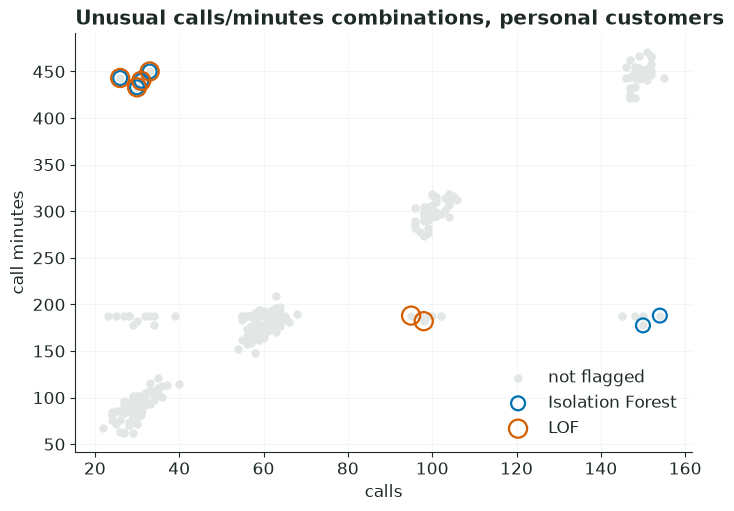


The 4 customers both methods flag make few calls but rack up a lot of minutes (long average call
length) -- an unusual but plausible calling pattern, with nothing pointing to a recording error,
so they are kept in the data.


In [20]:
# Write your solution here.
cols33 = ["calls", "call_minutes"]
personal_known = X_train[(X_train["contract"] == "personal") & (X_train["call_minutes_missing"] == 0)]
scaled33 = StandardScaler().fit_transform(personal_known[cols33])

iso_flag = IsolationForest(contamination=0.02, random_state=SEED).fit_predict(scaled33) == -1
lof_flag = LocalOutlierFactor(n_neighbors=20, contamination=0.02).fit_predict(scaled33) == -1
both_flag = iso_flag & lof_flag

print(f"Personal customers evaluated: {len(personal_known)}")
print(f"Isolation Forest flags: {iso_flag.sum()}")
print(f"Local Outlier Factor flags: {lof_flag.sum()}")
print(f"Flagged by both: {both_flag.sum()}")
print(personal_known.loc[both_flag, ["customer_id", "calls", "call_minutes"]])

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(personal_known["calls"], personal_known["call_minutes"], color=GRID, s=25, label="not flagged")
ax.scatter(personal_known.loc[iso_flag, "calls"], personal_known.loc[iso_flag, "call_minutes"],
           edgecolors=PALETTE[0], facecolors="none", s=100, linewidths=1.6, label="Isolation Forest")
ax.scatter(personal_known.loc[lof_flag, "calls"], personal_known.loc[lof_flag, "call_minutes"],
           edgecolors=PALETTE[1], facecolors="none", s=170, linewidths=1.6, label="LOF")
ax.set_xlabel("calls")
ax.set_ylabel("call minutes")
ax.set_title("Unusual calls/minutes combinations, personal customers")
ax.legend()
plt.show()

print("\nThe 4 customers both methods flag make few calls but rack up a lot of minutes (long average call")
print("length) -- an unusual but plausible calling pattern, with nothing pointing to a recording error,")
print("so they are kept in the data.")

### 3.4 Capping the Data

Find the 1st and the 99th percentiles of the data used among the training customers, and count the test customers that lie beyond them. Decide whether to cap the data at these bounds.

In [21]:
# Write your solution here.
p01, p99 = X_train["data_gb"].quantile([0.01, 0.99])
print(f"1st percentile: {p01:.2f} GB, 99th percentile: {p99:.2f} GB")

beyond = (X_test["data_gb"] < p01) | (X_test["data_gb"] > p99)
print(f"Test customers beyond those bounds: {beyond.sum()} of {len(X_test)}")
print(X_test.loc[beyond, ["customer_id", "package", "data_gb"]])

print("\nThese 6 test customers (none on the 'unlimited' package) use 78-94 GB, three to four times more")
print("than the heaviest training customer ever recorded. A pipeline fitted only on training data has no")
print("reliable way to tell a batch of data-entry slips from a genuine new usage pattern the training")
print("period never saw. Rather than discard or 'correct' them, they are capped to the training bounds --")
print("a safe default that stops a handful of unverifiable extreme test values from dominating any later")
print("scaling or distance-based step (Task 5.2 returns to exactly this group of customers).")

for frame in (X_train, X_test):
    frame["data_gb"] = frame["data_gb"].clip(p01, p99)

1st percentile: 2.69 GB, 99th percentile: 23.01 GB
Test customers beyond those bounds: 6 of 98
    customer_id      package  data_gb
9         91310       medium     90.4
14        91315       medium     89.6
26        91327        large     83.7
36        91337       medium     92.5
46        91347  extra large     94.1
65        91367        small     78.2

These 6 test customers (none on the 'unlimited' package) use 78-94 GB, three to four times more
than the heaviest training customer ever recorded. A pipeline fitted only on training data has no
reliable way to tell a batch of data-entry slips from a genuine new usage pattern the training
period never saw. Rather than discard or 'correct' them, they are capped to the training bounds --
a safe default that stops a handful of unverifiable extreme test values from dominating any later
scaling or distance-based step (Task 5.2 returns to exactly this group of customers).


## Task 4: Encoding and Scaling

### 4.1 Labels as Numbers

Turn every label into numbers in the way its kind calls for, learning from the training customers:

- the package keeps its order, from small to unlimited,
- a label without an order gets one column per category, a single column when it has two categories, and zeros for a category that the training customers never held, and
- the device model becomes its share of the training customers, with 0 for a model that the training customers never held.

Report the code of each package, the number of columns that the labels without an order become, and the share of the Lumo 4.

In [22]:
# Write your solution here.
package_order = ["small", "medium", "large", "extra large", "unlimited"]
package_enc = OrdinalEncoder(categories=[package_order]).fit(X_train[["package"]])
print("package codes:", dict(zip(package_order, range(len(package_order)))))

unordered_cols = ["contract", "origin", "payment", "handset"]
onehot_enc = OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False).fit(X_train[unordered_cols])
onehot_names = onehot_enc.get_feature_names_out(unordered_cols)
print(f"\nThe labels without an order become {len(onehot_names)} columns:")
print(list(onehot_names))

freq_enc = FrequencyEncoder().fit(X_train[["device_model"]])
lumo4_share = freq_enc.shares_["device_model"].get("Lumo 4", 0.0)
print(f"\nShare of Lumo 4 among the training customers: {lumo4_share:.4f}")

package codes: {'small': 0, 'medium': 1, 'large': 2, 'extra large': 3, 'unlimited': 4}

The labels without an order become 9 columns:
['contract_personal', 'origin_new number', 'origin_ported', 'origin_upgrade', 'payment_bank transfer', 'payment_card', 'payment_cash', 'payment_direct debit', 'handset_own device']

Share of Lumo 4 among the training customers: 0.2313


### 4.2 Comparable Scales

Bring every numeric column to a scale that suits it, and reduce the skew of the columns with a long right tail. Report the skew of the deposit before and after, the power that brings it closest to a normal distribution, and what the text messages need instead.

In [23]:
# Write your solution here.
numeric_cols = ["calls", "call_minutes", "data_gb", "lines", "instalment", "deposit", "sms"]
print("Skew of each numeric column:")
print(X_train[numeric_cols].skew().sort_values(ascending=False))

deposit_skew_before = X_train["deposit"].skew()
pt_deposit = PowerTransformer(method="box-cox").fit(X_train[["deposit"]])
deposit_skew_after = pd.Series(pt_deposit.transform(X_train[["deposit"]]).ravel()).skew()
print(f"\ndeposit skew before: {deposit_skew_before:.3f}")
print(f"deposit skew after Box-Cox: {deposit_skew_after:.3f}")
print(f"Box-Cox power (lambda) that brings deposit closest to normal: {pt_deposit.lambdas_[0]:.3f}")

print(f"\nsms includes 0 (min={X_train['sms'].min()}), and Box-Cox is only defined for strictly positive")
print("values, so sms needs the Yeo-Johnson power transform instead (it also accepts zero and negative values).")
pt_sms = PowerTransformer(method="yeo-johnson").fit(X_train[["sms"]])
sms_skew_after = pd.Series(pt_sms.transform(X_train[["sms"]]).ravel()).skew()
print(f"sms skew before: {X_train['sms'].skew():.3f}, after Yeo-Johnson: {sms_skew_after:.3f}")

Skew of each numeric column:
lines           5.060768
deposit         2.162741
sms             1.582089
data_gb         1.014171
call_minutes    0.900939
calls           0.835115
instalment      0.187506
dtype: float64

deposit skew before: 2.163
deposit skew after Box-Cox: -0.000
Box-Cox power (lambda) that brings deposit closest to normal: 0.029

sms includes 0 (min=0), and Box-Cox is only defined for strictly positive
values, so sms needs the Yeo-Johnson power transform instead (it also accepts zero and negative values).
sms skew before: 1.582, after Yeo-Johnson: -0.062


## Task 5: One Pipeline and Leakage

### 5.1 One Preparation

Join every step of Tasks 2 to 4 into one preparation that is fitted on the training customers and only applied to the test customers. Report the number of rows and columns of the prepared training and test tables, and confirm that they hold no missing values.

In [24]:
# Write your solution here.
skewed_cols = ["lines", "deposit", "sms"]
plain_numeric_cols = ["calls", "call_minutes", "data_gb", "instalment"]

preprocess = ColumnTransformer(
    transformers=[
        ("package", OrdinalEncoder(categories=[package_order]), ["package"]),
        ("unordered", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), unordered_cols),
        ("device_model", FrequencyEncoder(), ["device_model"]),
        ("skewed", PowerTransformer(method="yeo-johnson"), skewed_cols),
        ("numeric", StandardScaler(), plain_numeric_cols),
        ("flag", "passthrough", ["call_minutes_missing"]),
    ],
    remainder="drop",
)

X_train_prepared = preprocess.fit_transform(X_train)
X_test_prepared = preprocess.transform(X_test)
feature_names = preprocess.get_feature_names_out()

X_train_prepared = pd.DataFrame(X_train_prepared, columns=feature_names, index=X_train.index)
X_test_prepared = pd.DataFrame(X_test_prepared, columns=feature_names, index=X_test.index)

print(f"Prepared training table: {X_train_prepared.shape[0]} rows x {X_train_prepared.shape[1]} columns")
print(f"Prepared test table: {X_test_prepared.shape[0]} rows x {X_test_prepared.shape[1]} columns")
print(f"Missing values in the prepared training table: {X_train_prepared.isna().sum().sum()}")
print(f"Missing values in the prepared test table: {X_test_prepared.isna().sum().sum()}")

Prepared training table: 294 rows x 19 columns
Prepared test table: 98 rows x 19 columns
Missing values in the prepared training table: 0
Missing values in the prepared test table: 0


### 5.2 Fitted on All Customers

Fit the same preparation on all customers, the test customers included, and compare what it learns for the device models that only the test customers hold with what the preparation fitted on the training customers learns. Then show how the leak changes the test customers on the data used. Standardize the known test data once with the mean and the standard deviation of the training customers and once with those of all customers, compare how far they spread, and count the test customers beyond the 99th percentile of the data of the training customers and of all customers.

In [25]:
# Write your solution here.
X_all = pd.concat([X_train, X_test], axis=0)

freq_train_only = FrequencyEncoder().fit(X_train[["device_model"]])
freq_all = FrequencyEncoder().fit(X_all[["device_model"]])

test_only_models = sorted(set(X_test["device_model"]) - set(X_train["device_model"]))
print("Device models the test customers hold that training never saw:", test_only_models)
for model in test_only_models:
    learned_train = freq_train_only.shares_["device_model"].get(model, 0.0)
    learned_all = freq_all.shares_["device_model"].get(model, 0.0)
    print(f"  {model}: share learned from training only = {learned_train:.4f}, "
          f"share learned once test is included = {learned_all:.4f}")
print("Fitted on training alone these models are unseen (share 0). Folding test in gives them a")
print("nonzero share that a model trained on 'training only' features would never be able to produce.")

# Revisit data_gb *before* the 3.4 cap, to see what that cap was protecting against.
raw_all = pd.read_csv(DATA / "customers.csv", na_values="x").dropna(subset=["monthly_bill"])
raw_all["signed_on"] = pd.to_datetime(raw_all["signed_on"])
raw_all["data_gb"] = raw_all["data_gb"].fillna(data_gb_fill)  # same training-learned median as 2.2
raw_train_gb = raw_all.loc[raw_all["signed_on"] < split_date, "data_gb"]
raw_test_gb = raw_all.loc[raw_all["signed_on"] >= split_date, "data_gb"]
raw_all_gb = pd.concat([raw_train_gb, raw_test_gb])

train_mean, train_std = raw_train_gb.mean(), raw_train_gb.std()
all_mean, all_std = raw_all_gb.mean(), raw_all_gb.std()
print(f"\ndata_gb (uncapped): training mean={train_mean:.2f} std={train_std:.2f}")
print(f"data_gb (uncapped): all-customers mean={all_mean:.2f} std={all_std:.2f}")

test_scaled_train_stats = (raw_test_gb - train_mean) / train_std
test_scaled_all_stats = (raw_test_gb - all_mean) / all_std
print(f"\nTest data_gb standardized with TRAINING stats: spread (std) = {test_scaled_train_stats.std():.3f}, "
      f"range = [{test_scaled_train_stats.min():.2f}, {test_scaled_train_stats.max():.2f}]")
print(f"Test data_gb standardized with ALL-CUSTOMER stats: spread (std) = {test_scaled_all_stats.std():.3f}, "
      f"range = [{test_scaled_all_stats.min():.2f}, {test_scaled_all_stats.max():.2f}]")

p99_train = raw_train_gb.quantile(0.99)
p99_all = raw_all_gb.quantile(0.99)
beyond_train = (raw_test_gb > p99_train).sum()
beyond_all = (raw_test_gb > p99_all).sum()
print(f"\n99th percentile from training only: {p99_train:.2f} GB -> {beyond_train} test customers beyond it")
print(f"99th percentile from all customers: {p99_all:.2f} GB -> {beyond_all} test customers beyond it")
print("\nLetting the six extreme test customers into the fit drags the mean, the std and the 99th-percentile")

Device models the test customers hold that training never saw: ['Kestrel A4', 'Lumo 5']
  Kestrel A4: share learned from training only = 0.0000, share learned once test is included = 0.0077
  Lumo 5: share learned from training only = 0.0000, share learned once test is included = 0.0077
Fitted on training alone these models are unseen (share 0). Folding test in gives them a
nonzero share that a model trained on 'training only' features would never be able to produce.

data_gb (uncapped): training mean=9.44 std=4.28
data_gb (uncapped): all-customers mean=10.38 std=10.59

Test data_gb standardized with TRAINING stats: spread (std) = 4.595, range = [-1.55, 19.79]
Test data_gb standardized with ALL-CUSTOMER stats: spread (std) = 1.856, range = [-0.72, 7.90]

99th percentile from training only: 23.01 GB -> 6 test customers beyond it
99th percentile from all customers: 84.23 GB -> 4 test customers beyond it

Letting the six extreme test customers into the fit drags the mean, the std and the 

### 5.3 The Decisions

Record every preparation decision in a table, with the reason the data give for it.

In [26]:
full = pd.read_csv(DATA / "customers.csv", na_values="x")          # the file as read in 1.1 (all rows)
n_rows = len(full)


def p_of(column, compared_to):
    return pattern_tests.loc[(pattern_tests["column"] == column) & (pattern_tests["compared_to"] == compared_to),
                             "p_value"].iat[0]


def min_p(column, exclude=()):
    sub = pattern_tests[(pattern_tests["column"] == column) & ~pattern_tests["compared_to"].isin(exclude)]
    return sub["p_value"].min()


# --- instalment: does a gap coincide with handset == "own device"?
inst_gap = full["instalment"].isna()
own_device = full["handset"] == "own device"
gap_is_own = int((inst_gap & own_device).sum())

# --- call_minutes: how often is it missing per origin?
cm_gap_by_origin = full["call_minutes"].isna().groupby(full["origin"]).mean()
others = cm_gap_by_origin.drop("ported")

# --- data_gb / payment: is there any pattern left once the 100/200-line entries are corrected?
lines_fixed = full["lines"].where(~((full["contract"] == "personal") & (full["lines"] >= 100)), full["lines"] / 100)
dg_gap = full["data_gb"].isna()
dg_lines_fixed_p = stats.ttest_ind(lines_fixed[dg_gap], lines_fixed[~dg_gap], equal_var=False).pvalue

# --- lines (3.1/3.2), from the raw training customers and the IQR bound of 3.1
lines_flagged = raw_train[raw_train["lines"] > iqr_hi]
biz_flagged = lines_flagged[lines_flagged["contract"] == "business"]["lines"]
err_flagged = lines_flagged[lines_flagged["contract"] == "personal"]["lines"]
personal_normal = raw_train[(raw_train["contract"] == "personal") & (raw_train["lines"] <= iqr_hi)]["lines"]
err_before = "/".join(str(int(v)) for v in sorted(err_flagged))
err_after = "/".join(str(int(v)) for v in sorted(err_flagged / 100))

# --- calls / call_minutes (3.3)
minutes_per_call = personal_known["call_minutes"] / personal_known["calls"]

# --- data_gb cap (3.4), judged on the uncapped values
test_ids = X_test.loc[beyond, "customer_id"]
raw_beyond = raw.set_index("customer_id").loc[test_ids, "data_gb"]
raw_above = raw_beyond[raw_beyond > p99]
train_max_gb = raw_train["data_gb"].max()

# --- skew of the numeric columns (4.2)
skew = X_train[numeric_cols].skew()
skew_text = " / ".join(f"{c} {skew[c]:.1f}" for c in skewed_cols)
plain_text = " / ".join(f"{c} {skew[c]:.1f}" for c in plain_numeric_cols)

rows = []


def decide(issue, decision, reason):
    rows.append((issue, decision, reason))


decide(f"monthly_bill: {missing_counts['monthly_bill']} missing",
       "Dropped the rows",
       "It is the prediction target; a row with no label can't be trained on or checked against.")

decide(f"instalment: {missing_counts['instalment']} missing",
       f"0 for own-device customers; training median of financed customers ({instalment_fill:g}) otherwise",
       f"{gap_is_own} of {int(inst_gap.sum())} gaps are own-device customers and {int((own_device & ~inst_gap).sum())} "
       f"own-device customers have a value (chi2 p = {p_of('instalment', 'handset'):.1e}): the value doesn't exist, "
       f"it isn't unknown.")

decide(f"payment: {missing_counts['payment']} missing",
       f"Filled with the training mode ({payment_fill})",
       f"Smallest p over all {int((pattern_tests['column'] == 'payment').sum())} comparisons is "
       f"{min_p('payment'):.3f}: " + ("no pattern found." if min_p('payment') > 0.05 else "a pattern to check."))

decide(f"data_gb: {missing_counts['data_gb']} missing",
       f"Filled with the training median ({data_gb_fill:g})",
       f"Smallest p outside lines is {min_p('data_gb', exclude=['lines']):.3f}; the lines comparison gives "
       f"p = {p_of('data_gb', 'lines'):.4f} as recorded and p = {dg_lines_fixed_p:.3f} once the "
       f"{len(err_flagged)} wrong lines values (3.2) are corrected.")

decide(f"call_minutes: {missing_counts['call_minutes']} missing",
       "Filled with the training per-origin median "
       f"({', '.join(f'{o} {v:g}' for o, v in call_minutes_fill.items())}); kept a call_minutes_missing flag",
       f"Missingness depends on origin: {cm_gap_by_origin['ported']:.0%} of ported customers vs "
       f"{others.min():.0%}-{others.max():.0%} elsewhere (chi2 p = {p_of('call_minutes', 'origin'):.1e}); "
       f"the flag keeps the information that the gap itself carries.")

decide(f"lines: {len(biz_flagged)} business customers at {int(biz_flagged.min())}-{int(biz_flagged.max())}",
       "Kept as recorded",
       "Flagged by the IQR rule, but all are business contracts, where several SIM cards are routine.")

decide(f"lines: {len(err_flagged)} personal customers at {err_before}",
       "Divided by 100 (in X, X_train and X_test)",
       f"Personal customers otherwise have {int(personal_normal.min())}-{int(personal_normal.max())} lines; "
       f"dividing by 100 gives {err_after}, back inside that range.")

decide(f"calls/call_minutes: {int(both_flag.sum())} unusual personal customers",
       "Kept as recorded",
       f"Isolation Forest flags {int(iso_flag.sum())} and LOF {int(lof_flag.sum())}, "
       f"{int(both_flag.sum())} by both; their {minutes_per_call[both_flag].mean():.1f} min per call vs "
       f"{minutes_per_call[~both_flag].mean():.1f} for the rest is a long-call pattern, "
       f"not an impossible value.")

decide(f"data_gb: {int(beyond.sum())} test customers beyond the training bounds "
       f"({len(raw_above)} of them at {raw_above.min():.0f}-{raw_above.max():.0f} GB)",
       f"Capped to the training [{p01:.2f}, {p99:.2f}] GB bounds (1st-99th percentile)",
       f"The heaviest training customer used {train_max_gb:.1f} GB, so the {len(raw_above)} high ones are "
       f"{raw_above.min() / train_max_gb:.1f}-{raw_above.max() / train_max_gb:.1f} times that; capping stops them "
       f"dominating later scaling. With the 99th percentile fitted on all customers ({p99_all:.2f} GB) only "
       f"{beyond_all} test customers would lie above it (5.2).")

decide("package",
       "Ordinal encoding: " + ", ".join(f"{p}={i}" for i, p in enumerate(package_order)),
       "The categories have a natural order from small to unlimited.")

decide(", ".join(unordered_cols),
       f"One-hot encoding, a single column when binary ({len(onehot_names)} columns), unseen -> all zeros",
       "No order between the categories; one-hot invents none.")

decide("device_model",
       f"Frequency encoding ({X_train['device_model'].nunique()} training models, share of training customers)",
       f"One-hot would add {X_train['device_model'].nunique()} sparse columns; the encoding gives 0 to the "
       f"{len(test_only_models)} test-only models ({', '.join(test_only_models)}).")

decide(", ".join(skewed_cols),
       "Yeo-Johnson power transform",
       f"Right-skewed (skew {skew_text}); sms has a minimum of {X_train['sms'].min():g}"
       + (", which Box-Cox cannot take" if X_train["sms"].min() <= 0 else "")
       + f". The Box-Cox power for deposit would be {pt_deposit.lambdas_[0]:.2f}, "
       f"cutting its skew from {deposit_skew_before:.2f} to {deposit_skew_after:.2f}.")

decide(", ".join(plain_numeric_cols),
       "Standard scaling",
       f"Milder skew (skew {plain_text}); brought to the scale of the power-transformed columns.")

decide("customer_id, signed_on",
       "Dropped from the feature table",
       f"customer_id is unique for all {X_train['customer_id'].nunique()} training customers, so it identifies "
       f"and does not describe; signed_on only served the time split.")

decide("Train/test split and every fit",
       f"Time-based split at {split_date.date()}: {len(X_train)} training, {len(X_test)} test customers; "
       f"every fill, encoder and scaler fitted on training customers only",
       f"Fitting on all customers moves the data_gb standard deviation from {train_std:.2f} to {all_std:.2f} "
       f"and the 99th percentile from {p99_train:.2f} to {p99_all:.2f} GB, so test information would leak "
       f"into every step (5.2). Prepared tables: {X_train_prepared.shape[1]} columns, "
       f"{int(X_train_prepared.isna().sum().sum() + X_test_prepared.isna().sum().sum())} missing values.")

decisions = pd.DataFrame(rows, columns=["Column / issue", "Decision", "Reason"])
pd.set_option("display.max_colwidth", None)
decisions

,Column / issue,Decision,Reason
0,monthly_bill: 8 missing,Dropped the rows,It is the prediction target; a row with no label can't be trained on or checked against.
1,instalment: 41 missing,0 for own-device customers; training median of financed customers (900) otherwise,"41 of 41 gaps are own-device customers and 0 own-device customers have a value (chi2 p = 1.2e-86): the value doesn't exist, it isn't unknown."
2,payment: 22 missing,Filled with the training mode (direct debit),Smallest p over all 8 comparisons is 0.260: no pattern found.
3,data_gb: 19 missing,Filled with the training median (8.7),Smallest p outside lines is 0.066; the lines comparison gives p = 0.0024 as recorded and p = 0.004 once the 4 wrong lines values (3.2) are corrected.
4,call_minutes: 77 missing,"Filled with the training per-origin median (new number 182, ported 188, upgrade 177.5); kept a call_minutes_missing flag",Missingness depends on origin: 42% of ported customers vs 4%-7% elsewhere (chi2 p = 6.4e-18); the flag keeps the information that the gap itself carries.
5,lines: 12 business customers at 10-35,Kept as recorded,"Flagged by the IQR rule, but all are business contracts, where several SIM cards are routine."
6,lines: 4 personal customers at 100/100/100/200,"Divided by 100 (in X, X_train and X_test)","Personal customers otherwise have 1-4 lines; dividing by 100 gives 1/1/1/2, back inside that range."
7,calls/call_minutes: 4 unusual personal customers,Kept as recorded,"Isolation Forest flags 6 and LOF 6, 4 by both; their 14.8 min per call vs 3.1 for the rest is a long-call pattern, not an impossible value."
8,data_gb: 6 test customers beyond the training bounds (6 of them at 78-94 GB),"Capped to the training [2.69, 23.01] GB bounds (1st-99th percentile)","The heaviest training customer used 27.5 GB, so the 6 high ones are 2.8-3.4 times that; capping stops them dominating later scaling. With the 99th percentile fitted on all customers (84.23 GB) only 4 test customers would lie above it (5.2)."
9,package,"Ordinal encoding: small=0, medium=1, large=2, extra large=3, unlimited=4",The categories have a natural order from small to unlimited.
